In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import regex as re
import matplotlib as mpl
import datetime
import calendar
import os

In [40]:
SNs = [1557, 1558, 1559] # Float serial numbers
date = 20230803 # the date of the pressure test
datalocs = 'G:/Shared drives/WHOI Argo/BGC/Float Tracking/pressure_test_results/combined_test_results/' # where the pressure test data is located
secondloc = '_calcs_.xlsx'
ptfileloc= 'G:\\Shared drives\\WHOI Argo\\BGC\\Float Tracking\\pressure_test_data\\tankdata\\' # location of tank data
ptfilename ='PT_1557_1558_1559.xlsx' # tank data name

In [41]:
data0 = pd.read_excel(datalocs+str(SNs[0])+secondloc) # one float reading data
data1 = pd.read_excel(datalocs+str(SNs[1]) + secondloc) # second float
data2 = pd.read_excel(datalocs+str(SNs[2]) + secondloc) # third float
tankdata= pd.read_excel(ptfileloc+ptfilename) # reading tank data
tankdata['pressure']= tankdata['pressure']*0.68948 # converting from PSI to dbar
data = [data0, data1, data2] # moving to one dataframe

In [42]:
a = ['.', '_', '+'] # choose the marker types you want 

fig, fig0 = plt.subplots(7,1, figsize = (100,100)) #setting up figure
for i, d in enumerate(data): #each time through the loop is for a different float.
    j = 0
    fig0[j].scatter(data[i]['DATE'], data[i]['PH_9'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i])) # plotting date vs ph
    fig0[j].set_ylabel('pH', fontsize = 40) # adding ylabel
    fig0[j].legend(SNs, fontsize = 30) # legend showing which float is which line
    fig0[j].grid() #adding grid tiles

    j = j+1
    fig0[j].scatter(data[i]['DATE'], data[i]['PSAL'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i]))
    fig0[j].set_ylabel('salinity', fontsize = 40)
    fig0[j].legend(SNs, fontsize = 30)
    fig0[j].grid()

    j = j+1
    fig0[j].scatter(data[i]['DATE'], data[i]['OXYGEN'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i]))
    fig0[j].set_ylabel('oxygen', fontsize = 40)
    fig0[j].legend(SNs, fontsize = 30)
    fig0[j].grid()

    j = j+1
    fig0[j].scatter(data[i]['DATE'], data[i]['FCDOM'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i]))
    fig0[3].set_ylabel('fdom', fontsize = 40)
    fig0[j].legend(SNs, fontsize = 30)
    fig0[j].grid()

    j = j+1
    fig0[j].scatter(data[i]['DATE'], data[i]['FCHLA'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i]))
    fig0[j].set_ylabel('chla', fontsize = 40)
    fig0[j].legend(SNs, fontsize = 30)
    fig0[j].grid()

    j = j+1
    fig0[j].scatter(data[i]['DATE'], data[i]['BBP'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i]))
    fig0[j].set_ylabel('bbp', fontsize = 40)
    fig0[j].legend(SNs, fontsize = 30)
    fig0[j].grid()


    j = j+1
    fig0[j].scatter(data[i]['DATE'],data[i]['PRES'], marker = str(a[i]))
    fig0[j].scatter(tankdata['date'], tankdata['pressure'])
    fig0[j].set_xlabel('datetime', fontsize = 40)
    fig0[j].set_ylabel('Pressure', fontsize = 40)
    fig0[j].legend(['tankdata', SNs[0], SNs[1], SNs[2]], fontsize = 30)
    fig0[j].grid()
# ADDING COLORBAR
cmap = mpl.cm.coolwarm
norm = mpl.colors.Normalize(vmin = 0, vmax = 2000)
fig.subplots_adjust(hspace=0.3)
fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap = cmap), ax = fig0, orientation = 'vertical', label = 'PRESSURE (dbar)')

    



In [43]:
# SAVING PLOT

foldername = str(SNs[0]) + '_' + str(SNs[1]) + '_' + str(SNs[2]) # what do you want the save folder named

filepath = 'G://Shared drives//WHOI Argo//BGC//Float Tracking//pressure_test_results//ptplotting//' + foldername + '//' # where will this folder be

filename = str(date)+'_'+'results.svg' #what should the file name be

if not os.path.exists(filepath): # if the folder is non existent create a new folder
    os.makedirs(filepath)

fig.savefig(filepath+filename) # save the figure to google docs


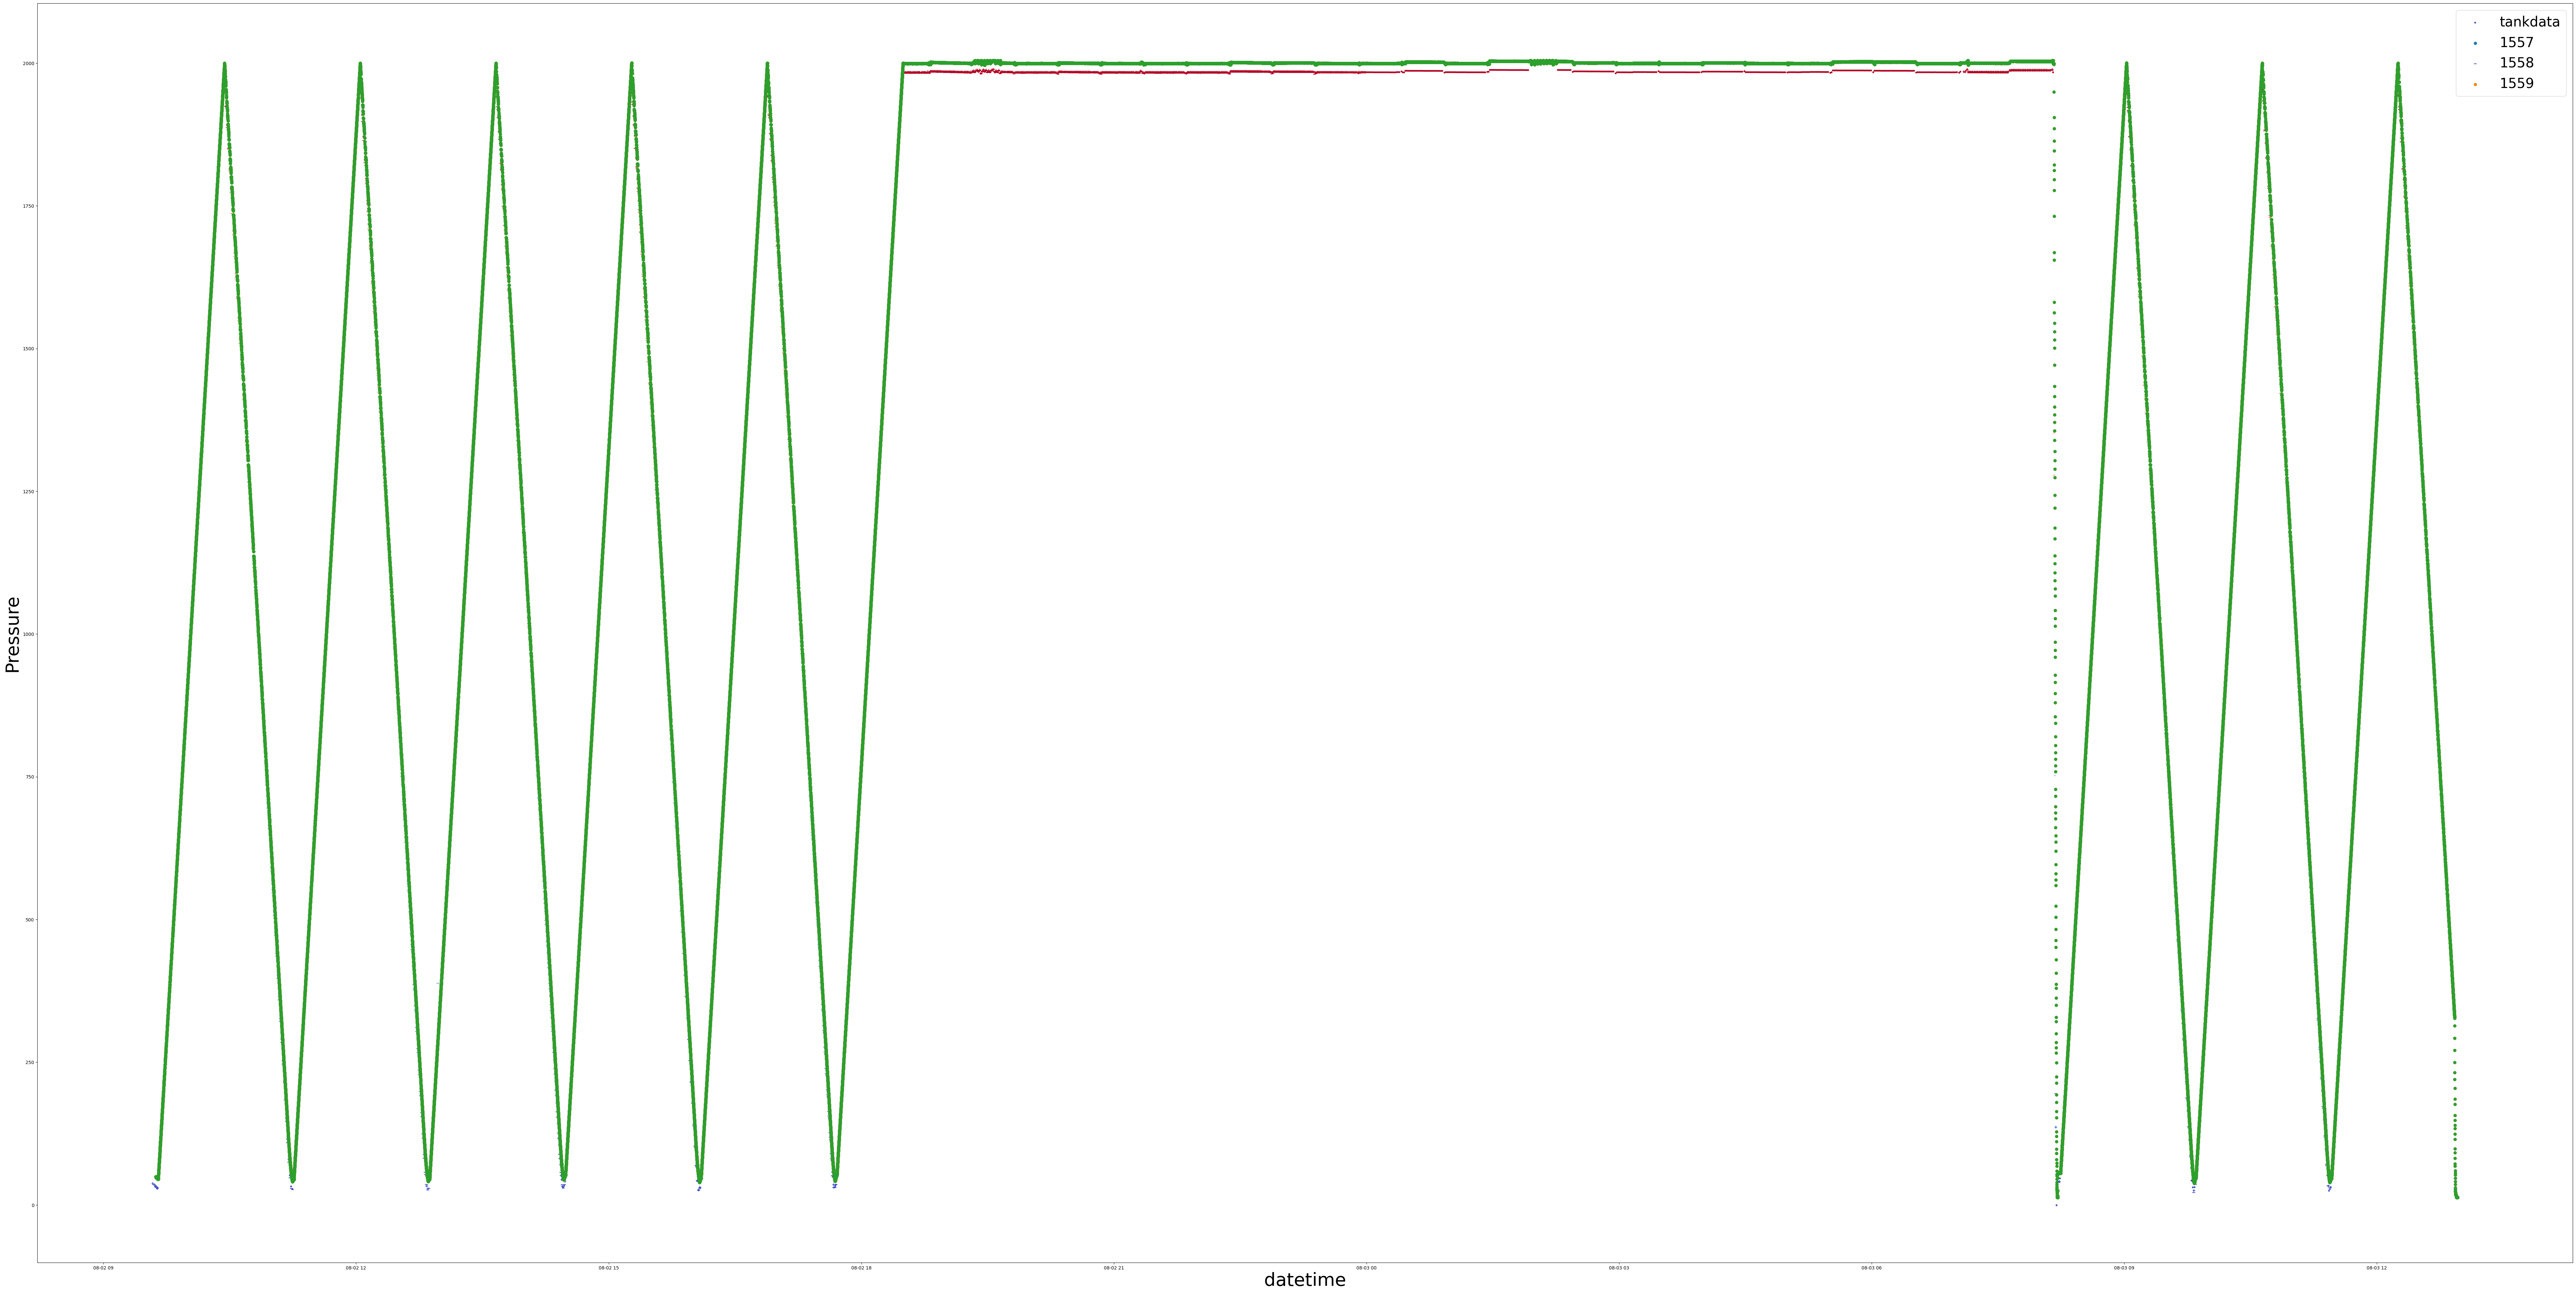

In [44]:
fig, fig1= plt.subplots(1,1, figsize = (100,50)) #setting up figure
for i, d in enumerate(data): #each time through the loop is for a different float.
    j = 0
    fig1.scatter(data[i]['DATE'], data[i]['PRES'], c = data[i]['PRES'], cmap = 'coolwarm', marker = str(a[i])) # plotting date vs ph
    fig1.scatter(tankdata['date'], tankdata['pressure'])

    fig1.set_ylabel('pH', fontsize = 40) # adding ylabel
    fig1.legend(SNs, fontsize = 30) # legend showing which float is which line
    fig1.grid() #adding grid tiles
    fig1.set_xlabel('datetime', fontsize = 40)
    fig1.set_ylabel('Pressure', fontsize = 40)
    fig1.legend(['tankdata', SNs[0], SNs[1], SNs[2]], fontsize = 30)
    fig1.grid()

In [45]:
# SAVING PLOT

foldername = str(SNs[0]) + '_' + str(SNs[1]) + '_' + str(SNs[2]) # what do you want the save folder named

filepath = 'G://Shared drives//WHOI Argo//BGC//Float Tracking//pressure_test_results//ptplotting//' + foldername + '//' # where will this folder be

filename = str(date)+'_'+'pressurecomp''_''results.pdf' #what should the file name be

if not os.path.exists(filepath): # if the folder is non existent create a new folder
    os.makedirs(filepath)

fig.savefig(filepath+filename) # save the figure to google docs